# Search trajectories: what changes with experience, and what makes a good session?

The earlier notebooks asked where mice go. This one asks what their paths look like, and answers two questions:

1. **Experience.** As mice get better at the task, do their search paths change character - straighter, faster, fewer pauses, less time along the walls?
2. **Good sessions.** When a mouse finds more targets in a session than it usually does, is that because its paths are different, or because it simply covers more ground?

**The path.** Shape is measured on the SLEAP body centroid, lightly smoothed. The point the task tracked online (the nose, as Bonsai saw it) sticks and jumps and is used here only for what it decides in the task: which cells have been entered. Distances are therefore shorter than in the earlier notebooks, which followed the nose (the body path is about 60% as long).

**The measures.** All are for the search itself: trial start to target found.

| Measure | Definition | A more efficient searcher would be... |
|---|---|---|
| Share of time moving | fraction of search time with the body moving faster than 50 px/s | higher |
| Speed while moving | distance / time moving (px/s) | higher |
| Turning | mean change of heading between successive 40 px steps of path (degrees) | lower |
| Straightness | over each 480 px stretch of path, the distance actually gained as a fraction of 480 px (1 = straight line) | higher |
| Share of path along walls | fraction of distance covered in the outer ring of the grid (within one cell of the frame edge), which never holds a target. The body cannot reach the frame edge, so in practice this is the body tight against a side wall; `occupancy_centroid.ipynb` maps it | lower |
| Yield | cells newly checked per 1000 px of path (task's point) | higher |

Turning and straightness are computed on the path resampled at equal steps of distance, so they describe its shape and do not depend on how fast it was run. For scale, the arena is 888 x 1968 px, a cell is 177 x 178 px, and a mouse's nose is about 165 px ahead of its centroid.

**The trap, and how it is avoided.** A search changes character as it drags on (section 2): the longer it has been going, the slower and more tortuous the path. A session with many long searches would therefore look tortuous for that reason alone, and sessions with many long searches are exactly the unsuccessful ones. So every search is split into phases by how long it has been going (0-4 s, 4-10 s, 10-25 s, over 25 s), each measure is computed within each phase, and the phases are averaged with the same fixed weights for every session. These **phase-matched** measures describe how a mouse moves at a given point in a search, whatever its mix of short and long searches.

Odor `x` and vision `v` sessions, the same nine mice in both; every mouse ran vision after odor, so the two are shown as one timeline. Each mouse contributes its first ten sessions of each experiment (x1 onward for odor; mouse 9000 ran only six vision sessions), and sessions are numbered 1 to 10 by their place in the mouse's own sequence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps
from scipy.ndimage import gaussian_filter1d

from src import config as cfg
from src.trials import USECOLS, discover_sessions, cell_rect
from src.trajectories import load_trajectories, load_sessions   # run `python -m src.trajectories` to rebuild output/trajectories*.csv

pd.set_option('display.width', 200, 'display.precision', 3)

EXPERIMENTS = ['odor', 'vision']
EXP_COLOR = {'odor': '#2a78d6', 'vision': '#7a52c7'}
EXP_LABEL = {'odor': 'Odor', 'vision': 'Vision'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

MOUSE = ['experiment', 'mouse']
SESSION = MOUSE + ['session', 'session_num']
PHASE_LABEL = ['0-4 s', '4-10 s', '10-25 s', 'over 25 s']

# name: (numerator, denominator, scale) - every measure is a ratio of two sums, so searches pool cleanly
MEASURES = {
    'share of time moving':        ('moving_s', 'search_s', 1),
    'speed while moving (px/s)':   ('path_px', 'moving_s', 1),
    'turning (deg per 40 px)':     ('turn_sum', 'turn_n', 180 / np.pi),
    'straightness (480 px)':       ('straight_sum', 'straight_n', 1),
    'share of path along walls':   ('wall_path_px', 'path_px', 1),
    'new cells per 1000 px':       ('cells_new', 'path_px', 1000),
}

def measures(d, by):
    """Each measure, pooled over the rows of d within groups."""
    sums = d.groupby(by).sum(numeric_only=True)
    return pd.DataFrame({name: scale * sums[num] / sums[den] for name, (num, den, scale) in MEASURES.items()})

tr = pd.concat([load_trajectories(e) for e in EXPERIMENTS], ignore_index=True)        # one row per search and phase
searches = tr.groupby(SESSION + ['trial'], as_index=False).sum(numeric_only=True).drop(columns=['phase', 'flip'])   # one row per search

## 1. Data

In [2]:
overview = searches.groupby('experiment').agg(
    mice=('mouse', 'nunique'), sessions=('session', lambda s: searches.loc[s.index].groupby(SESSION).ngroups), searches=('trial', 'size'),
    median_search_s=('search_s', 'median'), median_path_px=('path_px', 'median'))
display(overview.join(measures(tr, 'experiment')).loc[EXPERIMENTS].T)
print('mice with a session at each session number')
searches.groupby(['experiment', 'session_num']).mouse.nunique().unstack('session_num').astype('Int64')

experiment,odor,vision
mice,9.000,9.000
sessions,90.000,86.000
searches,10621.000,12129.000
median_search_s,7.268,6.041
median_path_px,2183.521,1956.302
share of time moving,0.776,0.792
speed while moving (px/s),321.195,340.495
turning (deg per 40 px),24.816,22.955
straightness (480 px),0.702,0.722
share of path along walls,0.226,0.144


mice with a session at each session number


session_num,1,2,3,4,5,6,7,8,9,10
experiment,,,,,,,,,,
odor,9,9,9,9,9,9,9,9,9,9
vision,9,9,9,9,9,9,8,8,8,8


Body paths for the first six searches longer than 5 s after trial 20, in one mouse's first odor session and its tenth vision session. The shaded ring is the wall zone; the square is the target cell; the dot is where the search started.

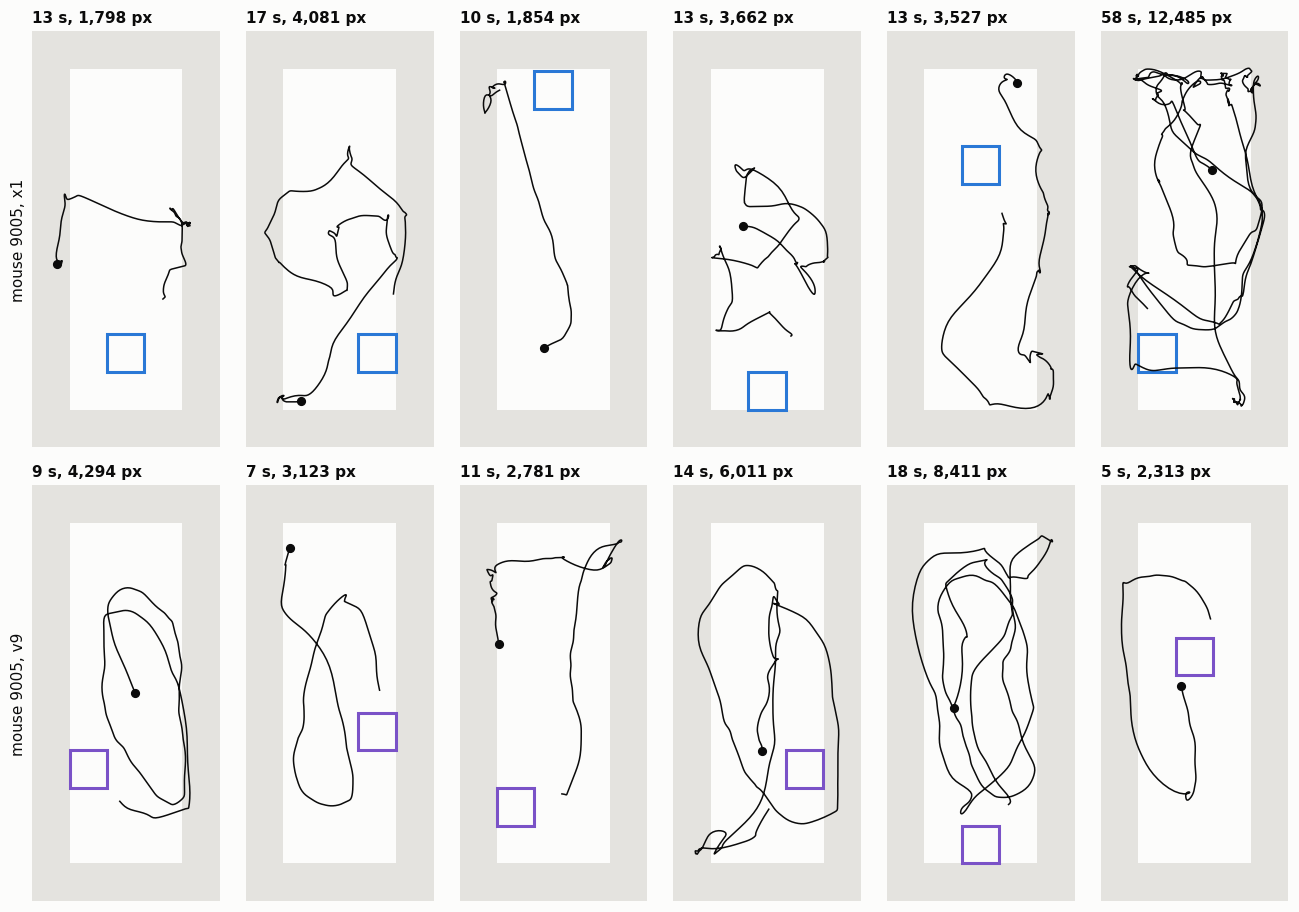

In [3]:
EXAMPLES = [('odor', '9005', 'x1'), ('vision', '9005', 'v9')]
BODY = [f'{cfg.TRAJ_POS}_x', f'{cfg.TRAJ_POS}_y']

fig, axes = plt.subplots(2, 6, figsize=(12, 8.4))
for row, (exp, mouse, session) in zip(axes, EXAMPLES):
    path = next(s['path'] for s in discover_sessions(exp) if (s['mouse'], s['session']) == (mouse, session))
    ev = pd.read_csv(path, usecols=USECOLS + BODY)
    info = searches[(searches.experiment == exp) & (searches.mouse == mouse) & (searches.session == session)]
    shown = info[(info.trial >= 20) & (info.search_s >= 5)].sort_values('trial').head(len(row))
    for ax, s in zip(row, shown.itertuples()):
        d = ev[ev.trial_number == s.trial]
        d = d.iloc[:int(np.flatnonzero(d.target_cell.isna())[0]) + 1]
        x, y = (gaussian_filter1d(d[c].to_numpy(float), cfg.SMOOTH_SIGMA) for c in BODY)
        ax.add_patch(plt.Rectangle((0, 0), cfg.FRAME_W, cfg.FRAME_H, color=GRID, lw=0))
        ax.add_patch(plt.Rectangle((cfg.CELL_W, cfg.CELL_H), cfg.FRAME_W - 2 * cfg.CELL_W, cfg.FRAME_H - 2 * cfg.CELL_H, color='#fcfcfb', lw=0))
        x0, y0, x1, y1 = cell_rect(int(d.target_cell.iloc[0]))
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=EXP_COLOR[exp], lw=2))
        ax.plot(x, y, color=INK, lw=1)
        ax.plot(x[0], y[0], 'o', color=INK, ms=5)
        ax.set(xlim=(0, cfg.FRAME_W), ylim=(0, cfg.FRAME_H), aspect='equal', xticks=[], yticks=[],
               title=f'{s.search_s:.0f} s, {s.path_px:,.0f} px')
        for side in ax.spines.values():
            side.set_visible(False)
    row[0].set_ylabel(f'mouse {mouse}, {session}', color=INK, fontsize=10)
plt.tight_layout(); plt.show()

## 2. A search changes as it drags on

Each measure by how long the search has been going. A search contributes to a phase only while it is still running, so the later phases come from the longer searches.

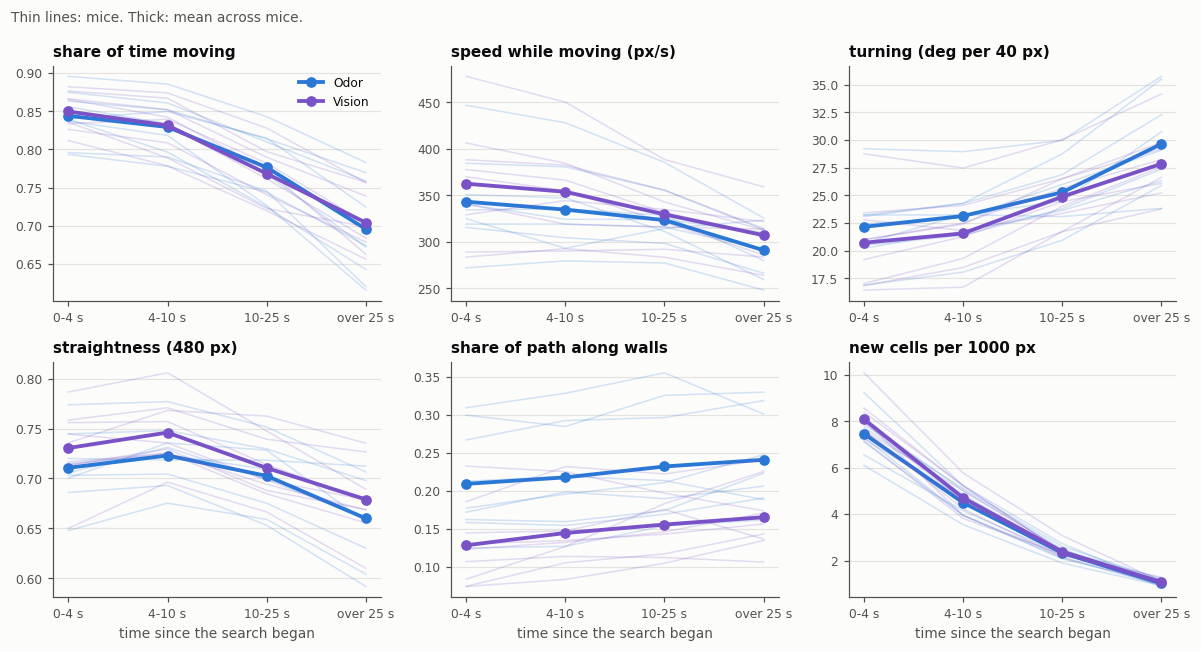

share of time moving  speed while moving (px/s)  turning (deg per 40 px)  straightness (480 px)  share of path along walls  new cells per 1000 px  searches  \
experiment phase                                                                                                                                                                    
odor       0-4 s                     0.844                    343.122                   22.161                  0.711                      0.209                  7.475     10621   
           4-10 s                    0.829                    334.604                   23.138                  0.723                      0.218                  4.497      7265   
           10-25 s                   0.777                    323.305                   25.282                  0.702                      0.232                  2.332      4202   
           over 25 s                 0.696                    290.883                   29.643                  0.660                      0.241                  1.011      1687   
vision     0-4 s                     0.850                    362.487                   20.725                  0.730                      0.128                  8.097     12129   
           4-10 s                    0.831                    353.821                   21.565                  0.746                      0.144                  4.706      7636   
           10-25 s                   0.768                    329.514                   24.886                  0.710                      0.155                  2.382      4064   
           over 25 s                 0.704                    307.005                   27.852                  0.679                      0.165                  1.069      1407   

                      share_of_search_time  
experiment phase                            
odor       0-4 s                     0.227  
           4-10 s                    0.217  
           10-25 s                   0.260  
           over 25 s                 0.296  
vision     0-4 s                     0.276  
           4-10 s                    0.244  
           10-25 s                   0.261  
           over 25 s                 0.219

In [4]:
by_phase = measures(tr, MOUSE + ['phase'])
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, name in zip(axes.flat, MEASURES):
    for exp in EXPERIMENTS:
        m = by_phase.loc[exp][name].unstack('phase')
        for mouse in m.index:
            ax.plot(range(m.shape[1]), m.loc[mouse], color=EXP_COLOR[exp], lw=1, alpha=0.2)
        ax.plot(range(m.shape[1]), m.mean(), color=EXP_COLOR[exp], lw=2.5, marker='o', ms=6, label=EXP_LABEL[exp])
    ax.set(xticks=range(len(PHASE_LABEL)), xticklabels=PHASE_LABEL, title=name)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
for ax in axes[-1]:
    ax.set_xlabel('time since the search began')
axes[0, 0].legend()
fig.suptitle('Thin lines: mice. Thick: mean across mice.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

phase_table = by_phase.groupby(['experiment', 'phase']).mean()
phase_table.index = phase_table.index.set_levels(PHASE_LABEL, level='phase')
phase_table.join(tr.groupby(['experiment', 'phase']).agg(searches=('trial', 'size'), share_of_search_time=('search_s', 'sum'))
                 .assign(share_of_search_time=lambda d: d.share_of_search_time / d.groupby('experiment').share_of_search_time.transform('sum'))
                 .rename(index=dict(enumerate(PHASE_LABEL)), level='phase'))

Every measure gets worse the longer a search has been going. Between the first 4 s and the part beyond 25 s:

- the share of time moving falls from 84-85% to 70%, and speed while moving by about 15%;
- turning rises from 21-22 to 28-30 degrees per step, and straightness falls from 0.71-0.73 to 0.66-0.68;
- the share of path along the walls creeps up (0.21 to 0.24 in odor, 0.13 to 0.17 in vision);
- yield collapses, from about 8 new cells per 1000 px to 1.

Only 12-16% of searches last beyond 25 s, but they are long: that phase holds 30% of all search time in odor sessions and 22% in vision. This is why the measures below are phase-matched.

## 3. With experience

One row per session. *Finds* is the number of targets found; *finds per search minute* divides that by the time spent searching, which removes the time spent drinking and waiting. The trajectory measures are phase-matched (see the top of the notebook).

The x-axis is each mouse's history: its ten odor sessions, then its ten vision sessions.

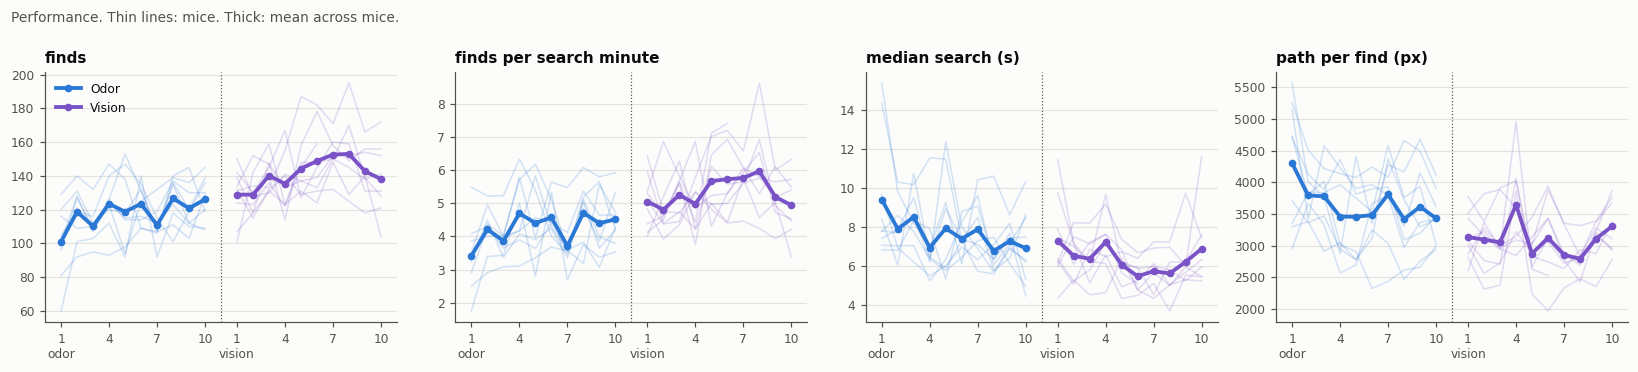

In [5]:
PHASE_WEIGHT = (tr.groupby('phase').search_s.sum() / tr.search_s.sum()).to_numpy()    # the same mix of early and late search for every session

def phase_matched(d, by):
    """Each measure computed within search phase, then averaged over phases with fixed weights."""
    m = measures(d, by + ['phase'])
    out = {}
    for name in MEASURES:
        wide = m[name].unstack('phase')
        out[name] = (wide * PHASE_WEIGHT).sum(axis=1) / (wide.notna() * PHASE_WEIGHT).sum(axis=1)
    return pd.DataFrame(out)

ses = searches.groupby(SESSION).agg(finds=('trial', 'size'), search_s=('search_s', 'sum'), path_px=('path_px', 'sum'),
                                    moving_s=('moving_s', 'sum'), median_search_s=('search_s', 'median'))
ses = ses.join(pd.concat([load_sessions(e) for e in EXPERIMENTS]).set_index(SESSION)).join(phase_matched(tr, SESSION)).reset_index()
ses['finds per search minute'] = 60 * ses.finds / ses.search_s
ses['path per find (px)'] = ses.path_px / ses.finds
ses['ground per search second (px/s)'] = ses.path_px / ses.search_s
ses['session distance (px)'] = ses.total_path_px
ses['share of session spent searching'] = ses.search_s / ses.duration_s
ses = ses.rename(columns={'median_search_s': 'median search (s)'})

PERFORMANCE = ['finds', 'finds per search minute', 'median search (s)', 'path per find (px)']
GROUND = ['session distance (px)', 'ground per search second (px/s)']
VISION_OFFSET = 11          # vision session n sits at n + this on the timeline

def timeline(ax, col):
    for exp in EXPERIMENTS:
        d = ses[ses.experiment == exp]
        x0 = VISION_OFFSET * (exp == 'vision')
        for mouse, g in d.groupby('mouse'):
            g = g.groupby('session_num')[col].mean()
            ax.plot(g.index + x0, g.values, color=EXP_COLOR[exp], lw=1, alpha=0.2)
        mean = d.groupby(['session_num', 'mouse'])[col].mean().groupby('session_num').mean()
        ax.plot(mean.index + x0, mean.values, color=EXP_COLOR[exp], lw=2.5, marker='o', ms=4, label=EXP_LABEL[exp])
    ax.axvline(VISION_OFFSET, color=MUTED, lw=0.8, ls=':')
    ax.set(title=col, xticks=[1, 4, 7, 10] + [VISION_OFFSET + n for n in (1, 4, 7, 10)], xticklabels=['1\nodor', '4', '7', '10', '1\nvision', '4', '7', '10'])
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col in zip(axes, PERFORMANCE):
    timeline(ax, col)
axes[0].legend()
fig.suptitle('Performance. Thin lines: mice. Thick: mean across mice.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

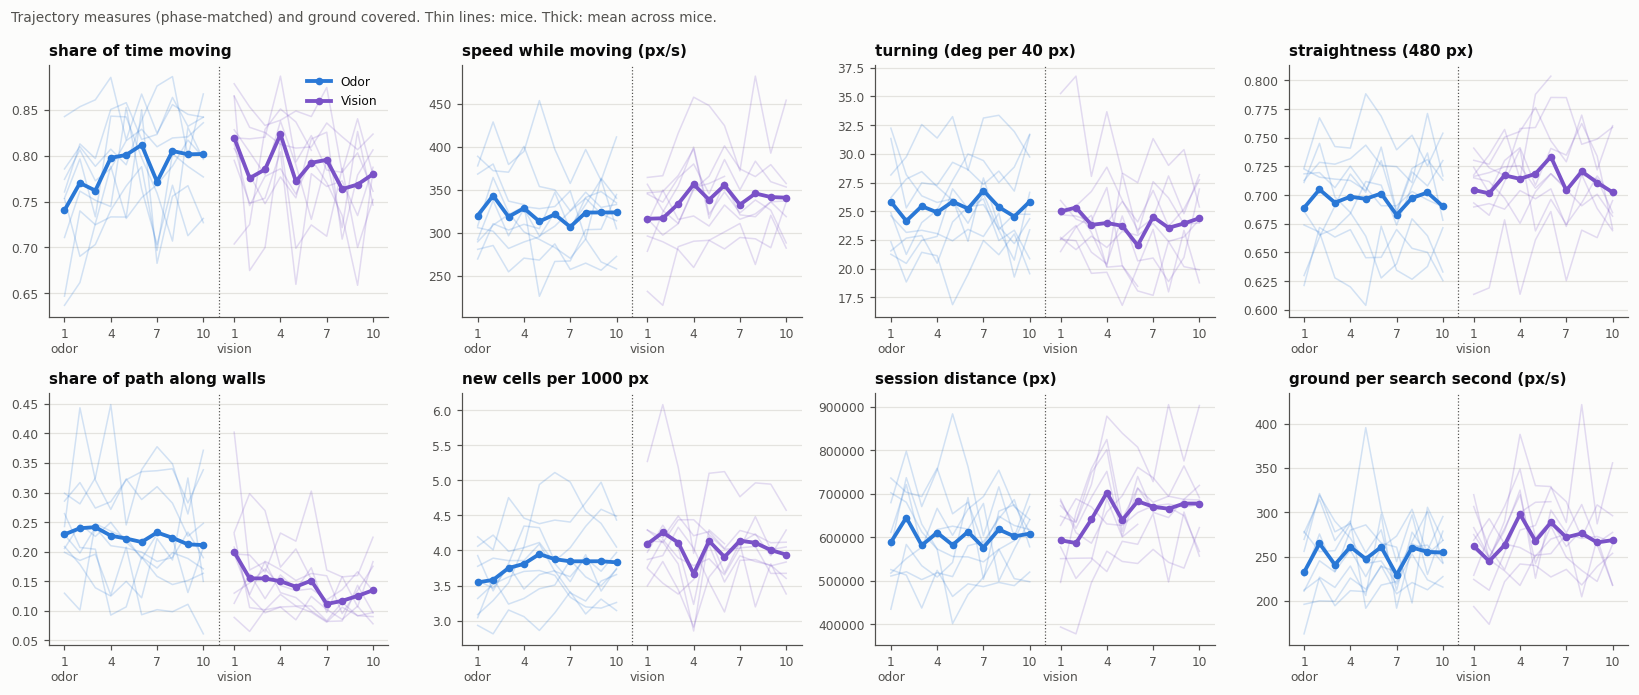

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for ax, col in zip(axes.flat, list(MEASURES) + GROUND):
    timeline(ax, col)
axes[0, 0].legend()
fig.suptitle('Trajectory measures (phase-matched) and ground covered. Thin lines: mice. Thick: mean across mice.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

How much each quantity changes, per mouse: the first two sessions of an experiment against its last four, and the last four odor sessions against the last four vision sessions.

In [7]:
def block_mean(d, cols, which):
    """Per-mouse mean over the first two or last four sessions of d (by session number)."""
    def pick(g):
        nums = np.sort(g.session_num.unique())
        return g[g.session_num.isin(nums[:2] if which == 'first' else nums[-4:])][cols].mean()
    return d.groupby('mouse')[['session_num'] + cols].apply(pick)

def change(a, b):
    """Percent change from a to b across mice (geometric), with a t-test on the log ratio."""
    ratio = np.log(b / a)
    return pd.DataFrame({'start': a.mean(), 'end': b.mean(), 'change (%)': 100 * (np.exp(ratio.mean()) - 1),
                         'p': sps.ttest_1samp(ratio, 0).pvalue,
                         'mice up': [f'{int((ratio[c] > 0).sum())}/{len(ratio)}' for c in ratio]})

cols = PERFORMANCE + list(MEASURES) + GROUND
odor, vision = ses[ses.experiment == 'odor'], ses[ses.experiment == 'vision']
experience = pd.concat({
    'within odor: first 2 -> last 4': change(block_mean(odor, cols, 'first'), block_mean(odor, cols, 'last')),
    'within vision: first 2 -> last 4': change(block_mean(vision, cols, 'first'), block_mean(vision, cols, 'last')),
    'late odor -> late vision': change(block_mean(odor, cols, 'last'), block_mean(vision, cols, 'last')),
}, axis=1)
experience

within odor: first 2 -> last 4                                       within vision: first 2 -> last 4                                       late odor -> late vision  \
                                                         start         end change (%)      p mice up                            start         end change (%)      p mice up                    start   
finds                                                  109.889     121.111     11.171  0.093     8/9                          128.889     145.944     13.002  0.015     9/9                  121.111   
finds per search minute                                  3.818       4.336     14.810  0.104     8/9                            4.930       5.543     12.128  0.093     6/9                    4.336   
median search (s)                                        8.652       7.211    -15.446  0.028     2/9                            6.911       6.146    -10.650  0.220     3/9                    7.211   
path per find (px)                                    4047.065    3567.472    -12.002  0.051     3/9                         3113.529    3009.258     -3.140  0.305     5/9                 3567.472   
share of time moving                                     0.755       0.795      5.395  0.040     6/9                            0.798       0.783     -1.779  0.436     1/9                    0.795   
speed while moving (px/s)                              331.662     319.357     -3.525  0.439     4/9                          316.524     340.901      8.025  0.061     7/9                  319.357   
turning (deg per 40 px)                                 24.996      25.639      2.729  0.565     6/9                           25.153      23.923     -4.507  0.162     4/9                   25.639   
straightness (480 px)                                    0.697       0.693     -0.533  0.783     4/9                            0.703       0.716      1.835  0.133     6/9                    0.693   
share of path along walls                                0.234       0.220     -8.296  0.501     4/9                            0.177       0.131    -24.332  0.065     2/9                    0.220   
new cells per 1000 px                                    3.562       3.842      7.632  0.153     5/9                            4.175       4.033     -2.895  0.163     2/9                    3.842   
session distance (px)                               616653.669  600972.831     -1.909  0.721     4/9                       589665.070  666253.809     13.712  0.012     9/9               600972.831   
ground per search second (px/s)                        248.668     249.989      1.492  0.802     4/9                          253.469     273.342      8.079  0.128     6/9                  249.989   

                                                                       
                                        end change (%)      p mice up  
finds                               145.944     20.288  0.002     9/9  
finds per search minute               5.543     28.135  0.011     8/9  
median search (s)                     6.146    -14.998  0.045     2/9  
path per find (px)                 3009.258    -14.941  0.014     1/9  
share of time moving                  0.783     -1.455  0.487     2/9  
speed while moving (px/s)           340.901      6.725  0.008     7/9  
turning (deg per 40 px)              23.923     -6.557  0.018     2/9  
straightness (480 px)                 0.716      3.282  0.027     7/9  
share of path along walls             0.131    -38.922  0.009     1/9  
new cells per 1000 px                 4.033      5.533  0.113     7/9  
session distance (px)            666253.809     10.705  0.010     8/9  
ground per search second (px/s)     273.342      8.916  0.037     7/9

**Mice get better across the odor sessions, and keep improving in vision.**
- *Within odor:* from the first two sessions to the last four, the median search falls from 8.7 to 7.2 s (7/9 mice), the path needed per find falls 12% (6/9 mice, p = 0.05) and targets found per session rise 11% (110 to 121; 8/9 mice, p = 0.09).
- *Within vision:* targets found rise a further 13% (129 to 146; 9/9 mice).
- *Odor to vision:* in their late vision sessions mice find 20% more targets than in their late odor sessions (9/9 mice), with 15% less path per find (8/9 mice).

**Within an experiment, the shape of the path does not change.**
- *Within odor:* the one trajectory measure that moves is pausing. The share of search time spent moving rises from 0.76 to 0.80 (p = 0.04, 6/9 mice). Speed while moving, turning and straightness change by 4% or less with no consistency across mice, and neither wall-following (-8%) nor yield per distance (+8%) changes reliably.
- *Within vision:* mice cover 14% more ground per session by the end (9/9 mice), and tend to run faster (+8%, 7/9 mice, p = 0.06) and spend less of their path along the walls (-24%, 7/9 mice, p = 0.07). Turning and straightness do not change reliably (-5% and +2%).

**Between experiments there is a modest shift, all in the direction of more vigorous movement.** From late odor to late vision: wall-following falls from 22% of the path to 13% (8/9 mice), distance covered per session rises 11% (8/9 mice), speed while moving rises 7% (7/9 mice), and paths are slightly straighter (turning -7%, straightness +3%; 7/9 mice each).

So tortuosity is not what improves as mice learn the task in the odor sessions; they pause less and need less path per target. Later they move away from the walls, cover more ground, and run somewhat faster and straighter.

## 4. What makes a good session?

Everything here is **within mouse**: each session is compared with the same mouse's other sessions in the same experiment, so differences between mice and between experiments drop out.

### Ground covered, or path needed?

The number of targets found per minute of searching is exactly

> finds per search minute = (share of time moving x speed while moving) / path per find

The first bracket is how much ground the mouse covers per minute; the second is how much ground it takes to find a target. Taking logs turns this into a sum, so the variation in finding rate across a mouse's sessions splits exactly into a share from each term.

Path per find needs one more check. Where the target is hidden is random, so a session can have short paths by luck alone. The **chance SD** column is the session-to-session spread each term would show if a mouse's searches were dealt out to its sessions at random (500 shuffles): spread at that level is luck, spread above it is a real difference between sessions.

In [8]:
TERMS = {'share of time moving': ('moving_s', 'search_s', +1), 'speed while moving': ('path_px', 'moving_s', +1), 'path per find': ('path_px', 'n', -1)}

def log_terms(d, session_id):
    """Per-session log finding rate and its terms, as deviations from the mouse's mean."""
    sums = d.assign(n=1).groupby(MOUSE + [session_id])[['n', 'search_s', 'path_px', 'moving_s']].sum()
    logs = pd.DataFrame({name: np.log(sums[num] / sums[den]) for name, (num, den, sign) in TERMS.items()})
    logs['finds per search minute'] = np.log(sums.n / sums.search_s)
    return logs - logs.groupby(MOUSE).transform('mean')

observed = log_terms(searches, 'session')
rng = np.random.default_rng(0)
shuffled = searches[MOUSE + ['session', 'search_s', 'path_px', 'moving_s']].copy()
chance = []
for _ in range(500):
    shuffled['dealt'] = shuffled.groupby(MOUSE).session.transform(lambda s: rng.permutation(s.to_numpy()))
    chance.append(log_terms(shuffled, 'dealt').groupby('experiment').std())
chance = pd.concat(chance, keys=range(len(chance)))

rows = {}
for exp in EXPERIMENTS:
    d = observed.loc[exp]
    rate = d['finds per search minute']
    for name in ['finds per search minute'] + list(TERMS):
        null = chance.xs(exp, level='experiment')[name]
        rows[(EXP_LABEL[exp], name)] = {
            'share of variation in finding rate': TERMS[name][2] * np.cov(rate, d[name])[0, 1] / rate.var() if name in TERMS else 1.0,
            'SD across sessions (%)': 100 * d[name].std(), 'chance SD (%)': 100 * null.mean(), 'chance 97.5th pct (%)': 100 * null.quantile(0.975)}
decomposition = pd.DataFrame(rows).T
decomposition

share of variation in finding rate  SD across sessions (%)  chance SD (%)  chance 97.5th pct (%)
Odor   finds per search minute                               1.000                  19.653         13.168                 15.257
       share of time moving                                  0.245                   6.095          3.137                  3.652
       speed while moving                                    0.210                   8.897          3.185                  3.715
       path per find                                         0.546                  13.703         10.687                 12.186
Vision finds per search minute                               1.000                  15.610         11.454                 13.186
       share of time moving                                  0.124                   5.431          2.767                  3.142
       speed while moving                                    0.292                   8.310          2.747                  3.195
       path per find                                         0.584                  12.853          9.657                 11.256

### Which trajectory measures go with a good session?

For each mouse, the correlation across its sessions between the number of targets found and each quantity (both as logs). This is done separately for the odor and the vision sessions, so each experiment has nine correlations, one per mouse. The table gives their mean, a t-test of the nine against zero, and how many of the nine are positive.

The second table repeats this without each experiment's first two sessions, to check that a relationship is not just the early learning seen in section 3.

In [9]:
def mouse_r(d, col, target='finds'):
    """One correlation per mouse, across that mouse's sessions in d."""
    return d.groupby('mouse')[[col, target]].apply(lambda g: np.corrcoef(np.log(g[col]), np.log(g[target]))[0, 1])

def summarize_r(r):
    z = np.arctanh(r)
    return {'mean r': np.tanh(z.mean()), 'p': sps.ttest_1samp(z, 0).pvalue, 'mice with r > 0': f'{int((r > 0).sum())}/{len(r)}'}

def goes_with_finds(d):
    return pd.concat({EXP_LABEL[exp]: pd.DataFrame({c: summarize_r(mouse_r(d[d.experiment == exp], c)) for c in CORRELATES}).T
                      for exp in EXPERIMENTS}, axis=1)

CORRELATES = ['finds per search minute'] + GROUND + ['path per find (px)', 'share of session spent searching'] + list(MEASURES)
first_two = ses.groupby(MOUSE).session_num.transform(lambda s: np.sort(s.unique())[1])
goes_with = goes_with_finds(ses)
display(goes_with)
print("without each mouse's first two sessions of the experiment")
goes_with_finds(ses[ses.session_num > first_two])

Odor                        Vision                       
                                 mean r      p mice with r > 0 mean r      p mice with r > 0
finds per search minute           0.941    0.0             9/9  0.943    0.0             9/9
session distance (px)             0.644  0.003             8/9  0.623    0.0             9/9
ground per search second (px/s)    0.72  0.003             9/9  0.631    0.0             9/9
path per find (px)               -0.754    0.0             0/9 -0.659    0.0             0/9
share of session spent searching -0.678  0.001             1/9 -0.707    0.0             0/9
share of time moving              0.614  0.002             9/9  0.198  0.286             6/9
speed while moving (px/s)         0.544  0.017             7/9  0.538    0.0             9/9
turning (deg per 40 px)          -0.514  0.045             2/9  -0.61  0.005             1/9
straightness (480 px)             0.481  0.051             7/9  0.591  0.012             8/9
share of path along walls        -0.407  0.051             2/9 -0.584  0.002             0/9
new cells per 1000 px             0.087  0.504             5/9  0.127  0.073             6/9

without each mouse's first two sessions of the experiment


Odor                        Vision                       
                                 mean r      p mice with r > 0 mean r      p mice with r > 0
finds per search minute           0.936    0.0             9/9  0.965    0.0             9/9
session distance (px)              0.72  0.001             9/9  0.382  0.023             6/9
ground per search second (px/s)   0.756    0.0             9/9  0.475  0.006             8/9
path per find (px)               -0.722    0.0             0/9 -0.732  0.001             1/9
share of session spent searching -0.689  0.002             1/9 -0.815    0.0             0/9
share of time moving              0.618  0.001             9/9  0.183  0.551             6/9
speed while moving (px/s)         0.626  0.005             8/9  0.293  0.039             6/9
turning (deg per 40 px)          -0.553   0.05             2/9 -0.558  0.036             1/9
straightness (480 px)             0.468  0.072             8/9   0.55  0.031             8/9
share of path along walls         -0.47  0.028             2/9 -0.401  0.035             2/9
new cells per 1000 px            -0.071  0.658             4/9   0.42  0.031             6/9

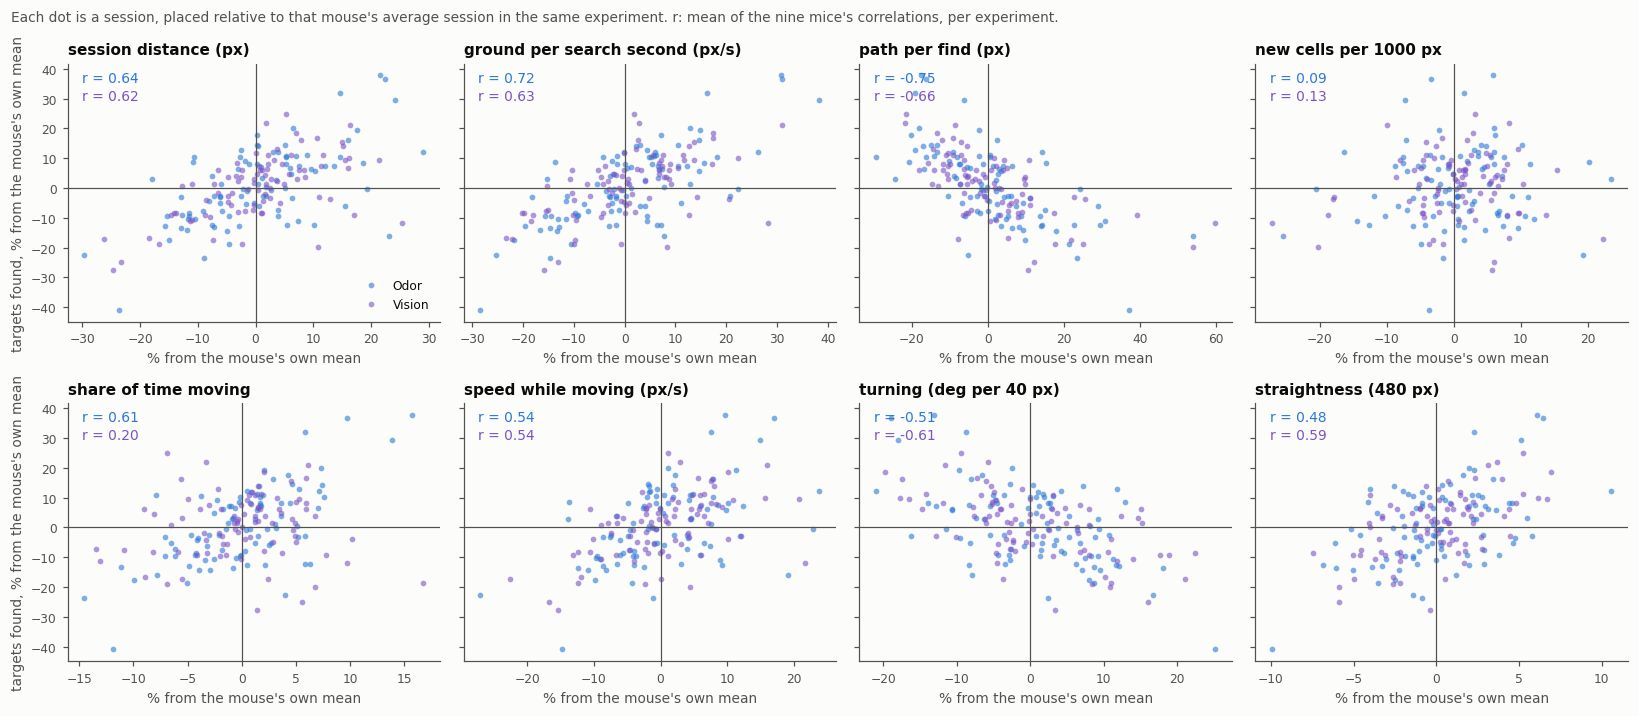

In [10]:
SHOWN = GROUND + ['path per find (px)', 'new cells per 1000 px', 'share of time moving', 'speed while moving (px/s)',
                  'turning (deg per 40 px)', 'straightness (480 px)']
dev = lambda col: 100 * (ses[col] / np.exp(np.log(ses[col]).groupby([ses.experiment, ses.mouse]).transform('mean')) - 1)

fig, axes = plt.subplots(2, 4, figsize=(15, 6.6), sharey=True)
for ax, col in zip(axes.flat, SHOWN):
    for exp in EXPERIMENTS:
        keep = ses.experiment == exp
        ax.scatter(dev(col)[keep], dev('finds')[keep], s=14, color=EXP_COLOR[exp], alpha=0.6, lw=0, label=EXP_LABEL[exp])
    ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
    ax.set(title=col, xlabel="% from the mouse's own mean")
    for i, exp in enumerate(EXPERIMENTS):
        ax.text(0.04, 0.93 - 0.07 * i, f"r = {goes_with.loc[col, (EXP_LABEL[exp], 'mean r')]:.2f}", transform=ax.transAxes, fontsize=9, color=EXP_COLOR[exp])
for ax in axes[:, 0]:
    ax.set_ylabel("targets found, % from the mouse's own mean")
axes[0, 0].legend(loc='lower right')
fig.suptitle("Each dot is a session, placed relative to that mouse's average session in the same experiment. r: mean of the nine mice's correlations, per experiment.",
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

### The measures move together

Correlations among the phase-matched measures across sessions, again within mouse (each as a deviation from that mouse's mean, pooled over mice).

In [11]:
together = np.log(ses[list(MEASURES)])
together = together - together.groupby([ses.experiment, ses.mouse]).transform('mean')
together.corr().round(2)

,share of time moving,speed while moving (px/s),turning (deg per 40 px),straightness (480 px),share of path along walls,new cells per 1000 px
share of time moving,1.00,0.25,-0.25,0.23,0.02,-0.17
speed while moving (px/s),0.25,1.00,-0.81,0.64,-0.16,-0.72
turning (deg per 40 px),-0.25,-0.81,1.00,-0.90,0.08,0.40
straightness (480 px),0.23,0.64,-0.90,1.00,-0.02,-0.23
share of path along walls,0.02,-0.16,0.08,-0.02,1.00,-0.20
new cells per 1000 px,-0.17,-0.72,0.40,-0.23,-0.20,1.00


The measures other than wall-following are one axis rather than four. Sessions in which a mouse runs faster are also the ones in which it turns less (r = -0.81) and runs straighter; turning and straightness are nearly the same measurement (r = -0.90). Wall-following is unrelated to the rest. Faster sessions also yield *fewer* new cells per distance (r = -0.72), so the extra ground is not better spent, only covered sooner.

## Summary

**With experience, the main changes are less pausing, more ground and less wall-following, not straighter paths.**
- Performance improves across the odor sessions (median search 8.7 to 7.2 s, 12% less path per find) and again across the vision sessions (13% more targets, 9/9 mice). Late vision sessions have 20% more finds than late odor sessions, in all nine mice.
- Compared at the same point in a search, turning and straightness do not change within either experiment. Late vision paths are slightly straighter than late odor ones (turning -7%, straightness +3%), alongside a 7% rise in running speed.
- The larger changes: the share of search time spent moving (0.76 to 0.80 across the odor sessions), distance covered per session (up 14% across the vision sessions) and wall-following (22% of the path in late odor sessions, 13% in late vision).

**A good session is both: more ground, and paths of a different character. They are the same thing.**
- The variation in finding rate across a mouse's sessions splits about evenly between ground covered per minute (45% in odor, 42% in vision) and path needed per find (55%, 58%).
- More than half of the variation in path per find is what chance alone produces (SD 13.7% against 10.7% expected in odor; 12.9% against 9.7% in vision), because where the target is hidden is random. The variation in ground covered is two to three times what chance produces.
- On a good day a mouse covers more ground (r = 0.64 with total session distance in odor, 0.62 in vision; positive in 17 of the 18 cases), and its paths at any given point in a search are faster (0.54, 0.54), straighter (0.48, 0.59), turn less (-0.51, -0.61) and follow the walls less (-0.41, -0.58). It also pauses less in the odor sessions (0.61, 9/9 mice), though not reliably in vision (0.20).
- But a given distance does not check more cells on a good day (r = 0.09 and 0.13). The mouse is not searching more cleverly; it is moving more vigorously, and vigorous movement is faster and straighter.
- Without each mouse's first two sessions these relationships keep their sign and mostly their size. In vision the ones with distance and speed weaken (0.38 and 0.29), and a positive relationship with yield appears (0.42, 6/9 mice).

**A search degrades as it drags on.** Past 25 s a mouse moves 70% of the time instead of 85%, turns about a third more, and checks one new cell per 1000 px instead of eight. Unsuccessful sessions have more of these long searches, which is why raw session averages overstate how much path shape differs between good and bad sessions.

**Reading the results.**
- Good sessions and vigorous movement go together, but the direction is open. A motivated mouse may run more and so find more; a mouse that happens to find targets quickly may be kept running by the rewards.
- Experience and modality cannot be separated: every mouse ran vision after odor, so the odor-to-vision differences may be further practice, the change of cue, or both.
- Yield is counted with the task's own tracking point, which sticks and jumps. If it skips cells when the mouse runs fast, that would contribute to the lower yield per distance in fast sessions.
- The chance SD treats a mouse's searches as interchangeable across its sessions. It is a floor for luck, not an exact figure.
- Phases match searches by elapsed time. A faster mouse has covered more ground by the same time, so phase-matching does not fully equate how much of the arena has been checked.
- Distances are in camera pixels (arena 888 x 1968 px); there is no calibration to cm here. Trial types are pooled, since the cue has little effect on search (notebooks 1-3).
- p-values are unadjusted, and the experience table alone holds 36 tests. The results relied on here are consistent across mice, not just below 0.05.
- Excluded: the odor `o` and `t` shaping sessions, sessions beyond each mouse's ten, trial 0 of each session, and trials with no target found.